# Harvesting under a strong Allee effect

<div style='border-left:5px solid #176b87;padding:12px;background:#176b8710'><b>Portable notebook</b><br>This file contains its Python source, configurations, synthetic datasets and recorded evidence. Run all cells from the top in a fresh kernel. No repository checkout or data download is needed.</div>

**Environment:** Python 3.11 or newer; install `numpy scipy matplotlib nbformat ipython` and `jax` (CPU). The bootstrap restores the included source into a temporary directory. The readable source files are also included in the companion download.

**Scope:** WP01, WP02, WP03, WP04, WP05. All population examples are synthetic. A short demonstrator is distinct from recorded final experiments. Explanations, equations and algorithms precede the corresponding code; interpretations and limitations follow.

**Execution budget:** classical experiments are bounded by their saved configs. PINN demonstrations use the stated notebook settings; the full historical parameter sweeps are read from tables, not silently retrained.

In [ ]:
# Restore the source and synthetic evidence embedded in this notebook.
import base64
import hashlib
import io
import os
import sys
import tempfile
from pathlib import Path
from zipfile import ZipFile

_payload = base64.b64decode(
    "..."
)
assert (
    hashlib.sha256(_payload).hexdigest()
    == "5d5355a6467a5483d444a52e358957154195004a1792ac28e2c3a27de24f903b"
)
ROOT = Path(tempfile.mkdtemp(prefix="mm-allee-notebook-"))
with ZipFile(io.BytesIO(_payload)) as _archive:
    for _entry in _archive.infolist():
        _path = (ROOT / _entry.filename).resolve()
        if not _path.is_relative_to(ROOT.resolve()):
            raise RuntimeError("Invalid embedded file path")
        _path.parent.mkdir(parents=True, exist_ok=True)
        _path.write_bytes(_archive.read(_entry))
sys.path.insert(0, str(ROOT / "src"))
os.environ["PYTHONPATH"] = str(ROOT / "src")
os.chdir(ROOT)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    import matplotlib

    matplotlib.use("Agg")
print("Restored bundled source and synthetic data:", ROOT)

In [ ]:
import os
from pathlib import Path

import mm_allee

ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "pyproject.toml").exists() and (path / "src/mm_allee").exists()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Run this notebook inside the project checkout")
os.chdir(ROOT)
print("Package:", mm_allee.__version__)

## 1. Foundations and Model A: steady populations under a fixed catch

<div style="border-left:5px solid #2a78d6;background:#2a78d614;padding:10px 14px;border-radius:4px"><strong>Question answered in this section</strong><br>If we keep catching the same amount every year, at which population levels can the stock stay steady, and does it return to those levels after a small disturbance? Where is the largest catch that still allows a steady population?</div>

**Owner:** WP01. **Data type:** analytical derivations and numerical root finding/simulation of the stated ODEs; no field observations are used.
The same functions generate the report figures through `python experiments/wp01/run.py --config configs/wp01.json --output results/wp01`.

### 1.1 Model and assumptions

We model one closed, well-mixed population $N(t)\ge 0$ in continuous time with constant parameters $r>0$, $K>0$, $0<A<K$:

$$\text{Logistic: } \frac{dN}{dt}=rN\Big(1-\frac{N}{K}\Big)-H,\qquad
\text{Model A: } \frac{dN}{dt}=rN\Big(1-\frac{N}{K}\Big)\Big(\frac{N}{A}-1\Big)-H,\qquad
\text{Model B: } \frac{dN}{dt}=rN\Big(1-\frac{N}{K}\Big)\Big(\frac{N}{A}-1\Big)-hN.$$

- The factor $(N/A-1)$ is the **strong Allee effect**: growth is negative for $0<N<A$, so $A$ is a minimum viable population.
- $H$ (population/time) is a fixed quota; $h$ (1/time) is a fixed harvesting effort.
- Deterministic, unstructured, no migration; parameters constant.
- **Boundary convention:** a quota cannot be taken from an extinct stock, so when $N$ reaches $0$ the simulation stops (absorbing extinction).

<div style="border-left:5px solid #eb6834;background:#eb683414;padding:10px 14px;border-radius:4px"><strong>Why it matters</strong><br>A threshold population plus a fixed catch can make a stock collapse suddenly and fail to recover, the pattern seen in several marine fisheries.</div>

### 1.2 Nondimensionalisation

Set $x=N/K$, $\tau=rt$, $a=A/K\in(0,1)$, $q=H/(rK)$, $e=h/r$. The chain rule gives
$\dfrac{dN}{dt}=\dfrac{d(Kx)}{d\tau}\dfrac{d\tau}{dt}=rK\dfrac{dx}{d\tau}$, so dividing by $rK$:

$$\frac{dx}{d\tau}=G(x)-q,\qquad G(x)=x(1-x)\Big(\frac{x}{a}-1\Big).$$

Four dimensional parameters collapse to two shape parameters, $a$ and $q$. The cell below checks numerically that the dimensional right-hand side equals $rK$ times the dimensionless one.

In [ ]:
import numpy as np

from mm_allee.models import Parameters, dimensional_rhs, rhs

p = Parameters(
    r=0.5, K=1000.0, A=200.0, H=150.0
)  # illustrative values: 1/yr, tonnes, tonnes, tonnes/yr
d = p.dimensionless()
N = np.array([0.0, 100.0, 200.0, 500.0, 800.0, 1000.0])
lhs = dimensional_rhs(N, "A", p)
scaled = p.r * p.K * rhs(N / p.K, "A", a=d["a"], harvest=d["q"])
print("a = A/K =", d["a"], "  q = H/(rK) =", d["q"])
print("dN/dt (t/yr):       ", np.round(lhs, 6))
print("rK * dx/dtau (t/yr):", np.round(scaled, 6))
print("max difference:", np.max(np.abs(lhs - scaled)))

### 1.3 Equilibria and stability: the method

<div style="border-left:5px solid #1baf7a;background:#1baf7a14;padding:10px 14px;border-radius:4px"><strong>Definitions</strong><br>An <b>equilibrium</b> $x_e$ solves $f(x_e)=0$: the population stays put. <b>Stability</b> asks what a small disturbance does. In one dimension the sign of $f$ on each side decides: $f>0$ below and $f<0$ above means <i>stable</i>; the reverse means <i>unstable</i>; the same sign on both sides means <i>semistable</i> (attracts from one side only).</div>

When $f'(x_e)\neq0$, linearising $\xi=x-x_e$ gives $\dot\xi\approx f'(x_e)\xi$: stable if $f'<0$, unstable if $f'>0$, with relaxation time $1/|f'(x_e)|$.
When $f'(x_e)=0$ the linearisation says nothing, and only the one-sided signs decide.

### 1.4 Logistic baseline with constant yield

$f(x)=x(1-x)-q=0 \Rightarrow x_\pm=\tfrac12\big(1\pm\sqrt{1-4q}\big)$ and $f'(x_\pm)=1-2x_\pm=\mp\sqrt{1-4q}$.

| harvest | equilibria | stability |
|---|---|---|
| $q=0$ | $0,\ 1$ | $0$ unstable ($f'=1$), $1$ stable |
| $0<q<\tfrac14$ | $x_-<x_+$ | $x_-$ unstable (harvest-made threshold), $x_+$ stable |
| $q=\tfrac14$ | $x=\tfrac12$ (double) | semistable: $f=-(x-\tfrac12)^2\le0$ |
| $q>\tfrac14$ | none | every population collapses |

So the maximum constant yield is $H_c=rK/4$ at $N=K/2$.

In [ ]:
from mm_allee.equilibria import equilibria_logistic

for q in [0.0, 0.1, 0.25, 0.3]:
    recs = equilibria_logistic(q)
    text = (
        ", ".join(f"x={r.x:.4f} ({r.stability}, f'={r.derivative:+.3f})" for r in recs)
        or "none: collapse"
    )
    print(f"q={q:<5} -> {text}")

### 1.5 Model A: shape of the production curve and the fold

$$G(x)=-\frac{x^3}{a}+\frac{(1+a)x^2}{a}-x,\qquad G'(x)=-\frac{3x^2}{a}+\frac{2(1+a)x}{a}-1.$$

- Signs of the factors: $G<0$ on $(0,a)$, $G>0$ on $(a,1)$, $G<0$ for $x>1$, $G>0$ for $x<0$.
- $G'(x)=0 \iff 3x^2-2(1+a)x+a=0$. Since $G'(a)=1-a>0$ and $G'(1)=(a-1)/a<0$, the larger root lies in $(a,1)$ and is the maximum:

$$x^*=\frac{1+a+\sqrt{1-a+a^2}}{3},\qquad q_c=G(x^*)=\frac{2(1-a+a^2)^{3/2}+(1+a)(2a-1)(a-2)}{27a}.$$

Dimensionally $N^*=Kx^*$ and $H_c=rKq_c$. The cell checks the closed form against an **independent** numerical maximisation.

In [ ]:
from scipy.optimize import minimize_scalar

from mm_allee.equilibria import fold_a
from mm_allee.models import growth

for a in [0.1, 0.2, 0.3, 0.5]:
    x_star, q_c = fold_a(a)
    best = minimize_scalar(
        lambda x: -growth(x, a), bounds=(a, 1), method="bounded", options={"xatol": 1e-12}
    )
    print(
        f"a={a}: formula x*={x_star:.6f}, q_c={q_c:.8f} | numerical max x={best.x:.6f}, G={-best.fun:.8f}"
    )

### 1.6 Model A: the four harvest regimes

Equilibria solve $G(x)=q$. Because $G$ rises on $(a,x^*)$ and falls on $(x^*,1)$:

| regime | physical equilibria | stability |
|---|---|---|
| $q=0$ | $0,\ a,\ 1$ | stable, **unstable (minimum viable population)**, stable |
| $0<q<q_c$ | $x_-\in(a,x^*)$, $x_+\in(x^*,1)$ | $x_-$ unstable, $x_+$ stable; the third cubic root is **negative** and excluded |
| $q=q_c$ | $x^*$ (double root) | **semistable**: $f<0$ on both sides, attracts from above only |
| $q>q_c$ | none | collapse from every start |

<div style="border-left:5px solid #eb6834;background:#eb683414;padding:10px 14px;border-radius:4px"><strong>Zero is not an equilibrium when q > 0</strong><br>$f(0)=-q<0$. Below $x_-$ the population keeps falling with speed at least $q$ near zero and hits $x=0$ in finite time. We stop there (absorbing extinction); continuing the ODE would give negative populations.</div>

### 1.7 Algorithm for the roots

<div style="border-left:5px solid #6250d6;background:#6250d614;padding:10px 14px"><strong>Algorithm used by the integrated classical model</strong><br>1. Obtain the critical control from the shared threshold provider.<br>2. Only exact equality to that computed control denotes the double root. Nearby distinct controls remain below or above the fold.<br>3. Below the fold, bracket the two roots; close to it solve their small offsets from the maximum so populations near one remain distinguishable.<br>4. Always find the excluded negative root; classify the two positive branches using the factored cubic's signs, with independent high-precision and trajectory checks.<br>5. Report root residuals, derivatives and stability. If floating-point output cannot distinguish the roots, raise an explicit resolution error.</div>

The $64\varepsilon$ scale is a numerical uncertainty diagnostic, not a rule that creates an equilibrium above the fold. WP01 records and WP03 basin classification now use the same computed threshold and root provider. Initial-population uncertainty is separately labelled `boundary_unresolved`.

Why not a generic polynomial solver? Near the fold it can return a complex pair with a tiny imaginary part, as the next cell illustrates.

In [ ]:
from mm_allee.equilibria import equilibria_a

a = 0.2
x_star, q_c = fold_a(a)
print("numpy.roots at q = q_c:", np.roots([-1 / a, (1 + a) / a, -1.0, -q_c]))
for q in [0.0, 0.3, q_c - 1e-10, q_c, 0.63]:
    print(f"\nq = {q:.12f}")
    for r in equilibria_a(a, q, include_excluded=True):
        print(
            f"  x={r.x:+.8f}  {r.stability:<10} mult={r.multiplicity}  f'={r.derivative:+.3e}  "
            f"signs=({r.left_sign},{r.right_sign})  residual={r.residual:.1e}"
        )

### 1.8 Geometry, phase lines and branch diagram

Equilibria are where the production curve meets the horizontal harvest line. Filled circles are stable, open circles unstable, half-filled semistable.

In [ ]:
import matplotlib.pyplot as plt

from mm_allee.equilibria_plots import branch_figure, perturbation_figure, production_figure

fig = production_figure(a=0.2, logistic_q=(0.1, 0.25, 0.35), allee_q=(0.25 * q_c, q_c, 1.2 * q_c))
plt.show()

**Interpretation.** In the logistic panel the population only has a threshold when harvested. In Model A the threshold exists even at zero harvest ($x=a$), and the harvest line moves it up. At $q=q_c$ the line touches the top of the hill: one semistable point. Above it nothing can be sustained.

In [ ]:
fig = branch_figure(a=0.2)
plt.show()

**Interpretation.** The stable branch (solid) and the collapse threshold (dashed) approach each other as the quota rises and meet at the fold $(q_c,x^*)$, a saddle-node bifurcation. Implicit differentiation of $G(x)=q$ gives $dx/dq=1/G'(x)$: negative on the upper branch, positive on the lower one. The safety margin $x_+-x_-$ shrinks like $\sqrt{q_c-q}$.

### 1.9 Checking the stability labels by simulation

Independent check: start $\delta=0.01$ above and below each equilibrium and integrate with the shared RK45 solver (event at $x=0$).

In [ ]:
fig = perturbation_figure(a=0.2, q=0.3, delta=0.01, tau_end=12.0)
plt.show()

**Interpretation.** Both starts near $x_+$ return to it (stable). Just above $x_-$ the stock recovers to $x_+$; just below, it falls and reaches zero in finite time (unstable threshold). This is the behaviour the sign test predicted.

<div style="border-left:5px solid #1baf7a;background:#1baf7a14;padding:10px 14px;border-radius:4px"><strong>Main result</strong><br>For a fixed quota, the persistent state and the collapse threshold move together and merge at the maximum quota $q_c$. A shock causes collapse only if it exceeds the margin $x_+-x_-$, which shrinks to zero at $q_c$; harvesting near $q_c$ therefore leaves almost no safety margin and very slow recovery.</div>

<div style="border-left:5px solid #eb6834;background:#eb683414;padding:10px 14px;border-radius:4px"><strong>Limitations</strong><br>Deterministic and unstructured (no demographic noise, which matters most near the threshold); phenomenological cubic growth; constant parameters; the quota is assumed to be taken exactly whenever $N>0$. Dimensional numbers are illustrative only.</div>

## 2. Proportional harvesting and recovery

<div style="border-left:5px solid #c87116;background:#c8711614;padding:10px 14px"><strong>Question:</strong> Does reducing the catch restore a collapsed population? Carry state through the whole experiment and distinguish recovery from explicit restocking.</div>

Owner: @AshChan07. These are synthetic model calculations, not observations.

**Question:** does a smaller catch when population declines guarantee recovery?
No: below the Allee threshold, natural growth is already negative.
At 100 tonnes an effort of 0.05/year removes 5 tonnes/year, but at 20 tonnes
it removes 1 tonne/year. We compare this with a constant catch using common units.

## Derivation before computation
With $x=N/K$, $\tau=rt$, $a=A/K$, $e=h/r$,
$$f_B(x)=x[(1-x)(x/a-1)-e].$$
The nonzero roots solve $x^2-(1+a)x+a(1+e)=0$, so
$$x_\pm=\frac{1+a\pm\sqrt{(1-a)^2-4ae}}2,\qquad e_c=\frac{(1-a)^2}{4a}.$$
For $e<e_c$, $f_B=-x(x-x_-)(x-x_+)/a$ has signs $-,+,-$ on the three positive intervals.
Thus the lower positive root is unstable (the basin boundary) and the upper root is stable.
Zero is stable because $f'_B(0)=-1-e<0$. At the fold, the factor is a square:
the field is negative on both sides, so attraction occurs only from above.
Above the threshold only zero remains. At zero effort, recover $0,a,1$.

**Algorithm:** compute the discriminant threshold; return zero; return no positive
roots above it, one double root at it, or two roots below it. Use the product of
roots for the smaller root to avoid cancellation. The `e` field is effort, not
Task 1's yield `q`. Independent high-precision polynomial and trajectory tests
check this implementation.

In [ ]:
import csv
import json
import os
from pathlib import Path

from IPython.display import Image, display

from mm_allee.model_b import critical_effort, equilibria_b
from mm_allee.wp02_experiment import run_experiment

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
for effort in [0, 0.4, critical_effort(0.2), 1.0]:
    print(effort, [(r.x, r.stability) for r in equilibria_b(0.2, effort)])

## Fair comparison definitions

1. **Initial catch:** $H=hN_0$. Set $H=\alpha H_c^A$ and solve for $h$; the logistic model also gets $H$.
2. **Threshold fraction:** match $H_A/H_c^A=h/h_c=H_L/H_c^L=\alpha$. Initial catches can differ.

Use $r=0.5$/year, $K=1000$ tonnes, $A=200$ tonnes; $N_0/K=0.15,0.4,0.9$ and $\alpha=0.5,1.2$.
Calculate theoretical outcomes from phase lines separately from the finite observation horizon ($\tau=30$).
Integrate actual B catch over time; stop A/logistic catch at extinction. Divide total catch by the full horizon.
A blank critical population indicates no populated equilibrium. Equal $r,K$ does not match
logistic and Allee production curves, so a universal ecological risk ranking would be unjustified.

## History algorithm

Use staircase controls from 0 to 1.3 times critical and back, with 12 increments each way,
12 units at the peak, and dwell times 1 and 3 on ordinary intervals. Carry every terminal state forward.
After returning to zero, wait 15 units, then compare a 20-unit unassisted hold with a run adding $0.6K$.
For A, record the first zero event and shut down harvest; the zero continuation is a declared policy.
For B, never use the cutoff to reset the state. Report only the first sampled $x\leq10^{-6}$,
not an exact extinction time. Paired boundary rows encode left/right states; only restocking changes population discontinuously.

The following executes the actual bounded CPU experiment and writes a manifest. It also reruns
all four restocking histories with tighter integration settings; errors must be below the
predeclared absolute limits, $2\times10^{-7}$ in population and event time.

In [ ]:
config = json.loads((ROOT / "configs/wp02.json").read_text())
output = ROOT / "results/wp02-notebook"
manifest = run_experiment(config, output, ROOT)
print(manifest["status"], manifest["elapsed_seconds"], "seconds")
display(Image(filename=str(output / "wp02_b_branches.png")))
display(Image(filename=str(output / "wp02_history.png")))

In [ ]:
with (output / "wp02_comparison.csv").open() as f:
    comparison = list(csv.DictReader(f))
for row in comparison:
    if float(row["initial_population"]) == 900 and float(row["fraction"]) == 0.5:
        print(
            row["protocol"],
            row["model"],
            "initial catch",
            round(float(row["initial_catch"]), 2),
            "final biomass",
            round(float(row["final_population"]), 2),
            row["theoretical_outcome"],
        )
for row in manifest["summary"]:
    print(row)

## Interpretation and limits

At equal initial catch (131.28 tonnes/year), the example from 900 tonnes persists for A/B
but collapses for the logistic model: the catch exceeds that model's 125 tonnes/year maximum.
At half of each threshold, all three persist from 900 tonnes, but catches differ.
This contrast is about calibration, not evidence that Allee growth always improves safety.

For both ramp speeds, unassisted A reaches extinction and B becomes very small.
Reducing harvest to zero fails to restore a population below $a=0.2$.
Adding $0.6K$ at zero harvest crosses this threshold and restores the population toward $K$.
This is history dependence with an intervention, **not a spontaneous closed hysteresis loop**.
A event times in the curated run are about 13.436601 and 34.612578 in $\tau$ units;
B's first sampled smallness times are 20.4 and 42.0. Dynamic delay is not a new equilibrium threshold.
The two schedules also change total exposure, not just ramp speed.

Refinement errors in the curated runs are below $2\times10^{-9}$; tiny B tails below solver
absolute tolerance have no claimed relative accuracy. Test checks include high-precision roots,
independent maximisation, perturbations, matched units, boundary continuity, insufficient and sufficient
restocking, numerical refinement and manifest checksums. See `docs/tasks/WP02_model_b.md` for the evidence map.

The integrated notebook uses current reviewed WP01 code and WP03's shared threshold/basin helpers.
Comparisons retain the validated range $0.05\leq a\leq0.95$ and conservatively exclude ambiguous near-fold inputs.
A near-boundary initial population is explicitly unresolved. Final group slides, human reviews and rehearsal remain pending.
Optional slowing-down experiments are deferred. Codex assisted drafting and implementation;
human understanding has not been certified.

**Presentation check:** why does zero remain stable when effort falls back to zero?
Explain the sign of natural growth below the Allee threshold before quoting a formula.

## 3. Collapse thresholds, finite-time extinction and basins
<div style="border-left:4px solid #16803d;padding:10px"><strong>WP03 analysis implemented.</strong> Synthetic deterministic models; final group integration, human reviews and Devam's detailed learning review remain pending.</div>

For a well-mixed population, assume constant \(r>0\), \(0<A<K\), nonnegative harvest, no delays/age structure or other species. Put \(x=N/K,\ \tau=rt,\ a=A/K,\ q=H/(rK),\ e=h/r\). Then
\[
x'=G(x)-q\quad(A),\qquad x'=G(x)-ex\quad(B),\qquad
G(x)=-x^3/a+(1+a)x^2/a-x.
\]
**Threshold derivation.** \(G'=(-3x^2+2(1+a)x-a)/a\). The larger stationary point is
\(x_*=(1+a+\sqrt{1-a+a^2})/3\), in \((a,1)\), with \(G''(x_*)<0\);
the smaller point lies below a. Thus \(q_c=G(x_*)\) and
\(N_*=(K+A+\sqrt{K^2-KA+A^2})/3,\ H_c=rKq_c\).
For B, maximise \(P(x)=G(x)/x=(1-x)(x/a-1)\):
\(P'=(1+a-2x)/a,\ P''=-2/a\), so
\(e_c=(1-a)^2/(4a)\), \(h_c=re_c\).
The logistic class maximum is \(1/4\), giving \(H_{c,\mathrm{logistic}}=rK/4\).
H and h have different units; threshold comparisons also depend on production calibration.

**Algorithm:** compute closed-form thresholds; check them against independent bounded numerical maxima of expanded polynomials; classify basins before any extinction integration.

In [ ]:
import csv
import json
import subprocess
import sys
from pathlib import Path

from IPython.display import Image, display

from mm_allee.models import Parameters
from mm_allee.thresholds import dimensional_thresholds

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "configs/wp03.json").exists() and (p / "src/mm_allee").exists()
)
config = json.loads((ROOT / "configs/wp03.json").read_text())
parameters = Parameters(**config["parameters"])
print("Synthetic parameters:", vars(parameters))
print("Dimensional thresholds:", dimensional_thresholds(parameters))

### Basins and critical cases
For \(0<q<q_c\), A has two positive roots \(x_-<x_+\) and signs \(-,+,-\): below the lower root extinction, above it approach to the upper root. Exact roots remain equilibria. For B,
\[
x_\pm=(1+a\pm\sqrt{(1-a)^2-4ae})/2.
\]
At positive roots \(f'_B=xP'\), so the lower is unstable and upper stable; zero has derivative \(-(1+e)<0\).

| Control | A | B |
|---|---|---|
| Zero | Below a approaches zero asymptotically; above a tends to 1 | Same positive-state basins |
| Below fold | Below lower root reaches zero; above tends to upper root | Below lower root approaches zero; above tends to upper root |
| At fold | Below double root reaches zero; above approaches it | Below double root approaches zero; above approaches it |
| Above fold | Every finite positive start reaches zero | Every positive start approaches zero |

Exact initial equilibria stay there in all rows. At a fold the derivative is zero but signs on both sides are negative: **semistable**, attracting only from above.
The classifier explicitly recognises returned roots and marks non-exact starts within \(2\,10^{-12}\) of an unstable/semistable boundary unresolved. It does not merge adjacent harvest controls into the fold or decide survival from a finite horizon.

Numerically, compute the B upper root first and use the quadratic root product `lower = a*(1+e)/upper` to avoid cancellation for small a; the exact fold remains an explicit repeated root. The integrated WP01–WP03 APIs use the same threshold and branch providers and exact equality to the computed critical control. Adjacent controls retain distinct topology; numerical and initial-state uncertainty are reported separately.


### Extinction integral and solver checks
On a reaching-zero A path,
\[
\tau_{\rm ext}=\int_0^{x_0}\frac{du}{q-G(u)},\qquad
t_{\rm ext}=\tau_{\rm ext}/r=\int_0^{N_0}\frac{dN}{H-g(N)}.
\]
For a subcritical start below the barrier the denominator is continuous and positive over the whole path; at/above an intervening equilibrium the extinction integral is inapplicable. For \(q>q_c\), \(G\le q_c\) gives \(\tau_{\rm ext}\le x_0/(q-q_c)\).
For zero-yield A and B, smoothness/uniqueness exclude a positive trajectory reaching zero in finite time.

**Algorithm:** classify -> integrate only reaching-zero paths -> compare quadrature with two RK45 tolerances and independently expanded-polynomial DOP853 -> retain every case/status. No equilibrium pole is crossed. Blank times mean no finite extinction or unresolved boundary, not zero.

RK45 uses a shared-stage 5(4) pair for adaptive error control. We take the fifth-order state, locate the first downward zero event for positive-yield A, and include its endpoint without adding a zero tail. Output times are separate from adaptive internal steps. Quadrature error estimates and local RK tolerances are not rigorous global error bounds. References: [SciPy solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), [quad](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.quad.html).

**Difficult endpoint handling:** near the subcritical barrier, a logarithmic variable removes the vanishing linear factor. At the computed fold an elementary partial-fraction expression evaluates the extinction integral (`fold_closed_form`, no quadrature-error estimate). This avoids missed endpoint contributions for close-below-fold starts. Root rounding is separate from integration error. See `docs/WP03_EXPLAINED.md` for a basics-first explanation and the derivation.

Near a subcritical boundary, \(d\tau_{\rm ext}/dx_0 = 1/[q-G(x_0)] \sim 1/[f_A'(x_-)(x_--x_0)]\). Rounding in the initial state or root is amplified as the gap shrinks; small integration error alone does not justify extra digits.


In [ ]:
outputs = {
    "analysis": ROOT / "results/wp03-notebook",
    "reference": ROOT / "results/wp03-reference-notebook",
}
commands = [
    ("analysis", "experiments/wp03/run.py", "configs/wp03.json"),
    ("reference", "experiments/wp03/generate_reference.py", "configs/wp03_reference.json"),
]
for label, script, configuration in commands:
    completed = subprocess.run(
        [
            sys.executable,
            str(ROOT / script),
            "--config",
            str(ROOT / configuration),
            "--output",
            str(outputs[label]),
        ],
        cwd=ROOT,
        check=True,
        capture_output=True,
        text=True,
    )
    print(completed.stdout.strip())


def read_rows(filename):
    with (outputs["analysis"] / filename).open(newline="") as stream:
        return list(csv.DictReader(stream))


evidence = read_rows("wp03_event_validation.csv")
assert all(row["status"] == "passed" for row in evidence)
print(
    "Largest recorded event difference in dimensionless time:",
    max(float(row["max_abs_error_tau"]) for row in evidence),
)
display(Image(filename=str(outputs["analysis"] / "wp03_basins.png")))
display(Image(filename=str(outputs["analysis"] / "wp03_extinction.png")))

### Interpret the synthetic curves
The default \(r=0.7,K=100,A=20\) gives \(N_*=70.55050\), \(H_c=36.75966\), \(h_c=0.56\); logistic gives \(17.5\).
The 427 extinction evaluations retain non-finite outcomes rather than turning them into zero. Initial zero is omitted on the logarithmic time axis. Solid basin boundaries mark critical initial populations; the finite colour grid does not replace exact equilibrium classification.

At fixed reaching-zero initial population, increasing catch reduces extinction time. Approaching a basin boundary can make that time very large. A finite simulation horizon without an event does not settle whether extinction happens later. The six event checks include the fold from below and supercritical passage; the observed differences are much smaller than the declared \(2\,10^{-7}+5\,10^{-7}\tau_{\rm ext}\) acceptance tolerance.

Basin colour regions meet exactly at control/critical = 1; the fold is drawn as a line, so persistence cells do not extend above it. Every WP03 figure is exported as PNG/EPS/vector PDF; extensionless report references select the PDF under pdflatex.


### Why collapse can look delayed: the bottleneck
With \(q=q_c+\delta,\ y=x-x_*\), the exact cubic expansion is
\[
q-G(x)=\delta+\beta y^2+y^3/a,\qquad \beta=\sqrt{1-a+a^2}/a.
\]
For a fixed start above \(x_*\), the trajectory crosses a slow region. Integrating the leading denominator gives
\[
\int\frac{dy}{\delta+\beta y^2}
=\frac{\arctan(y\sqrt{\beta/\delta})}{\sqrt{\beta\delta}},
\quad \tau_{\rm ext}\sim\pi/\sqrt{\beta\delta}.
\]
The full near-fold integral is evaluated with \(y=\sqrt{\delta/\beta}\tan\theta\) to resolve its narrow peak.
This is passage after the equilibria disappear, distinct from relaxation to a stable equilibrium. A start already below the bottleneck need not have this divergence. At the fold, approach from above is algebraic, \(y\simeq y_0/(1+\beta y_0\tau)\).

In [ ]:
rows = read_rows("wp03_bottleneck.csv")
for row in rows:
    print("delta/qc =", row["fraction_above_fold"], "| tau*sqrt(delta) =", row["scaled_time"])
print("Leading scaled-time limit:", rows[0]["asymptotic_scaled_time"])
display(Image(filename=str(outputs["analysis"] / "wp03_bottleneck.png")))

### Optional results: sensitivity and sustainable yield
Holding other dimensional r,K,A fixed, \(g_N(N_*)=0\) eliminates the derivative of \(N_*\) from the maximum:
\[
H_{c,r}=H_c/r,\quad H_{c,K}=rN_*^2(N_*/A-1)/K^2,\quad
H_{c,A}=-rN_*^2(1-N_*/K)/A^2.
\]
Also
\[
h_{c,r}=h_c/r,\quad h_{c,K}=\tfrac r4(1/A-A/K^2),\quad
h_{c,A}=\tfrac r4(-K/A^2+1/K).
\]
Central differences check these derivatives; elasticities are \((p/C)C_p\). An a sweep at fixed r,K is a different experiment.

A's stable-branch yield supremum \(H_c\) lies at the semistable cliff, with no control margin.
For B, \(Y(h)=hN_+(h)=g(N_+(h))\). The production maximiser is on the upper branch, so
\(h_{\rm MSY}=g(N_*)/N_*<h_c,\ Y_{\rm MSY}=H_c\).
Independent bounded numerical maximisation checks the optimum. The example effort margin at MSY is about 6.96%; the initial state must still exceed the unstable root. Separate illustrative A/B policies are not a universal risk ranking.

In [ ]:
summary = json.loads((outputs["analysis"] / "wp03_summary.json").read_text())
print(json.dumps(summary, indent=2))
display(Image(filename=str(outputs["analysis"] / "wp03_sensitivity_yield.png")))
display(Image(filename=str(outputs["reference"] / "wp03_rk45_reference.png")))

### Handoff, reproduction and limitations
The early handoff retains six clean A/B CSVs (606 points). WP05 owns noise, frozen splits, inverse PINN/ODE fitting and held-out validation; WP04 supplies the shared neural engine. Keep known conditions/fixed external scales separate from evaluation truth, and never fit against held-out clean values or hidden unknown parameters.

Exact commands and test/evidence mapping: **docs/WP03_ANALYSIS.md**. The experiment regenerates tables and PNG/EPS; manifests record versions, units, tolerances and source/file hashes. All data are synthetic; no empirical species-level conclusion follows.

The report, notebook and EPS files required by the course must ultimately be integrated with all five tasks. **scripts/check_submission_ready.py** aggregates missing final artifacts, unfinished sections and metadata; a successful WP03 run does not make the final group submission ready. Reviews and non-author reproduction remain required.

AI assistance: OpenAI ChatGPT/Codex for this implementation, mathematical writing, tests and documentation, recorded in docs/AI_USAGE.md. Devam's detailed understanding review remains pending as requested.

## 4. Forward PINNs

**Question.** If a small neural network is given only the ODE and the initial condition, how well does it predict the population, compared with a standard solver? All data are *synthetic and dimensionless* ($x=N/K$, $\tau=rt$). The domain is $\tau\in[0,T]$ ($T=10$; for Model A, $T$ is the extinction time) and $x\in[0,1]$. The setting below is the **same one used for the inverse problem** (Section 5).

**Equations.** Model A: $\dot x=G(x)-q$; Model B: $\dot x=G(x)-ex$; $G(x)=x(1-x)(x/a-1)$. Write $\dot x=f(x)$.

**Network with a hard initial condition.** A fully connected network $N(s;\theta)$ with layer sizes $(1,32,32,1)$ (JAX, float64) and the $\tanh$ activation, with fixed time scaling $s=\tau/T$, defines

$$\hat x(\tau)=x_0+s\,N(s;\theta),$$

so $\hat x(0)=x_0$ **exactly for any weights**: no initial-condition loss is needed. Automatic differentiation with respect to physical time applies the chain rule $d\hat x/d\tau=T^{-1}\,d\hat x/ds$ (with the product rule on $s\,N$).

**Loss.** At $n=300$ fixed uniform collocation times $\tau_i\in[0,T]$:

$$R(\tau)=\frac{d\hat x}{d\tau}-f(\hat x),\qquad \mathcal L(\theta)=\frac1n\sum_i R(\tau_i)^2 .$$

**Algorithm.** (1) fixed collocation grid; (2) $\hat x$ and $d\hat x/d\tau$ by `jax.grad` + `vmap`; (3) $\mathcal L$; (4) Adam for 1000 iterations at learning rate $10^{-3}$ (about $2/7$ of the 3500-iteration budget) to reach a good region, then L-BFGS for 2500 iterations with the tolerance stop switched off, to converge. No solver solution is used as a label. For A the training interval ends at the extinction time, so the zero tail never enters the residual.

**Evaluation.** Dense DOP853 reference (rtol $10^{-12}$), separate from training. Metrics: RMSE, MAE, global relative $L^2$ (reported in scientific notation), max error, max error where $x_{\rm ref}<0.05$ (near-zero error), negative samples, runtime. A prediction containing NaN or infinity is *never scored* (it is labelled invalid and cannot count as accurate); a run that raises an exception is recorded as failed. A run is *inaccurate* if relative $L^2>5\times10^{-2}$ (threshold fixed beforehand).


In [ ]:
# Live demo (a few seconds on CPU): short run (100 Adam + 500 L-BFGS), Model B regular, seed 0, final design.
# A short budget is not the final result; compare with the curated table below.
import sys

sys.path.insert(0, "experiments/wp04")
import run as wp04

from mm_allee.pinn.train_forward import evaluate_prediction, predict

case = dict(model="B", a=0.2, harvest=0.3, x0=0.8, tau_end=10.0)
ref = dict(method="DOP853", rtol=1e-12, atol=1e-14, n_points=1001)
tau, x_ref, hit = wp04.reference_trajectory(case, ref)
training = {
    "activation": "tanh",
    "lr": 1e-3,
    "n_collocation": 300,
    "adam_iters": 100,
    "lbfgs_iters": 500,
}
res = wp04.run_pinn(case, 0, {"training": training}, hit)
ev = evaluate_prediction(predict(res.params, res.config, tau), x_ref)
print({k: (f"{v:.3e}" if isinstance(v, float) else v) for k, v in ev.items()})
print(f"{res.wall_seconds:.1f} s, final physics loss {res.history['loss'][-1]:.3e}")

## How the setting was chosen

The choice was made in two steps, and the second corrected the first.

1. **Activation at learning rate $10^{-2}$.** tanh, swish and sigmoid were compared with a rule fixed beforehand (most accurate runs of 18; seeds 0/1/42): swish 17/18, tanh 11/18, sigmoid 10/18. This varied the activation at one learning rate only.
2. **Joint study with the inverse problem.** A pre-registered study varied the knobs the two problems must share and scored each candidate by *(forward runs accurate of 18) + (inverse fits recovered of 18)*. The 64-wide network was dropped after its first candidate was slower and less accurate (score 23 against 28 at width 32). The network learning rate turned out to be the dominant factor ($10^{-3}$ beats $10^{-2}$ for both activations); tanh and swish at $10^{-3}$ tie on the score, the tie-break selects tanh, and on fresh seeds the two are not clearly separated by this small seed sample.

Both tables are loaded from `artifacts/tables/`. *Caveat:* the selection used the same seeds as the final sweep, so its accuracy is optimistic; the fresh-seed confirmation further down is the unbiased evidence.

In [ ]:
import csv  # noqa: F811  (an earlier fragment imports csv in the assembled notebook)

print("Step 1: activation at lr 1e-2 (artifacts/tables/wp04_activation_selection.csv)")
for r in csv.DictReader(open("artifacts/tables/wp04_activation_selection.csv")):
    print(
        f"  {r['activation']:8s} accurate {r['n_accurate']:>2s}/{r['n_runs']}  geomean rel L2 {float(r['geomean_relative_l2']):.2e}"
    )
print("\nStep 2: shared-settings study, width 32 (artifacts/tables/shared_stage1_summary.csv)")
for r in csv.DictReader(open("artifacts/tables/shared_stage1_summary.csv")):
    print(
        f"  {r['candidate']:22s} forward {r['forward_accurate']:>2s}/{r['forward_runs']}  inverse {r['inverse_recovered']:>2s}/{r['inverse_fits']}  "
        f"score {r['score']:>2s}  selected: {r['selected']}"
    )

## Curated final results (loaded, not retrained)

The table is `artifacts/tables/wp04_forward_metrics.csv`, produced by
`python experiments/wp04/run.py --config configs/wp04_final.json --output results/wp04 --artifacts artifacts` (about 1.2 min on CPU; see `artifacts/manifests/wp04_forward.json` and the pinned versions in `wp04_forward_requirements.txt`).


In [ ]:
rows = list(csv.DictReader(open("artifacts/tables/wp04_forward_metrics.csv")))


def fmt(v):
    return f"{float(v):.2e}" if v else "-"


print(
    f"{'case':13s}{'method':7s}{'seed':5s}{'status':12s}{'rel L2':>10s}{'max err':>10s}{'near-0':>10s}{'neg':>5s}{'sec':>7s}"
)
for r in rows:
    print(
        f"{r['case']:13s}{r['method']:7s}{r['seed']:5s}{r['status']:12s}{fmt(r['relative_l2']):>10s}"
        f"{fmt(r['max_abs']):>10s}{fmt(r['max_abs_near_zero']):>10s}{r['boundary_violations']:>5s}{float(r['wall_seconds']):7.2f}"
    )

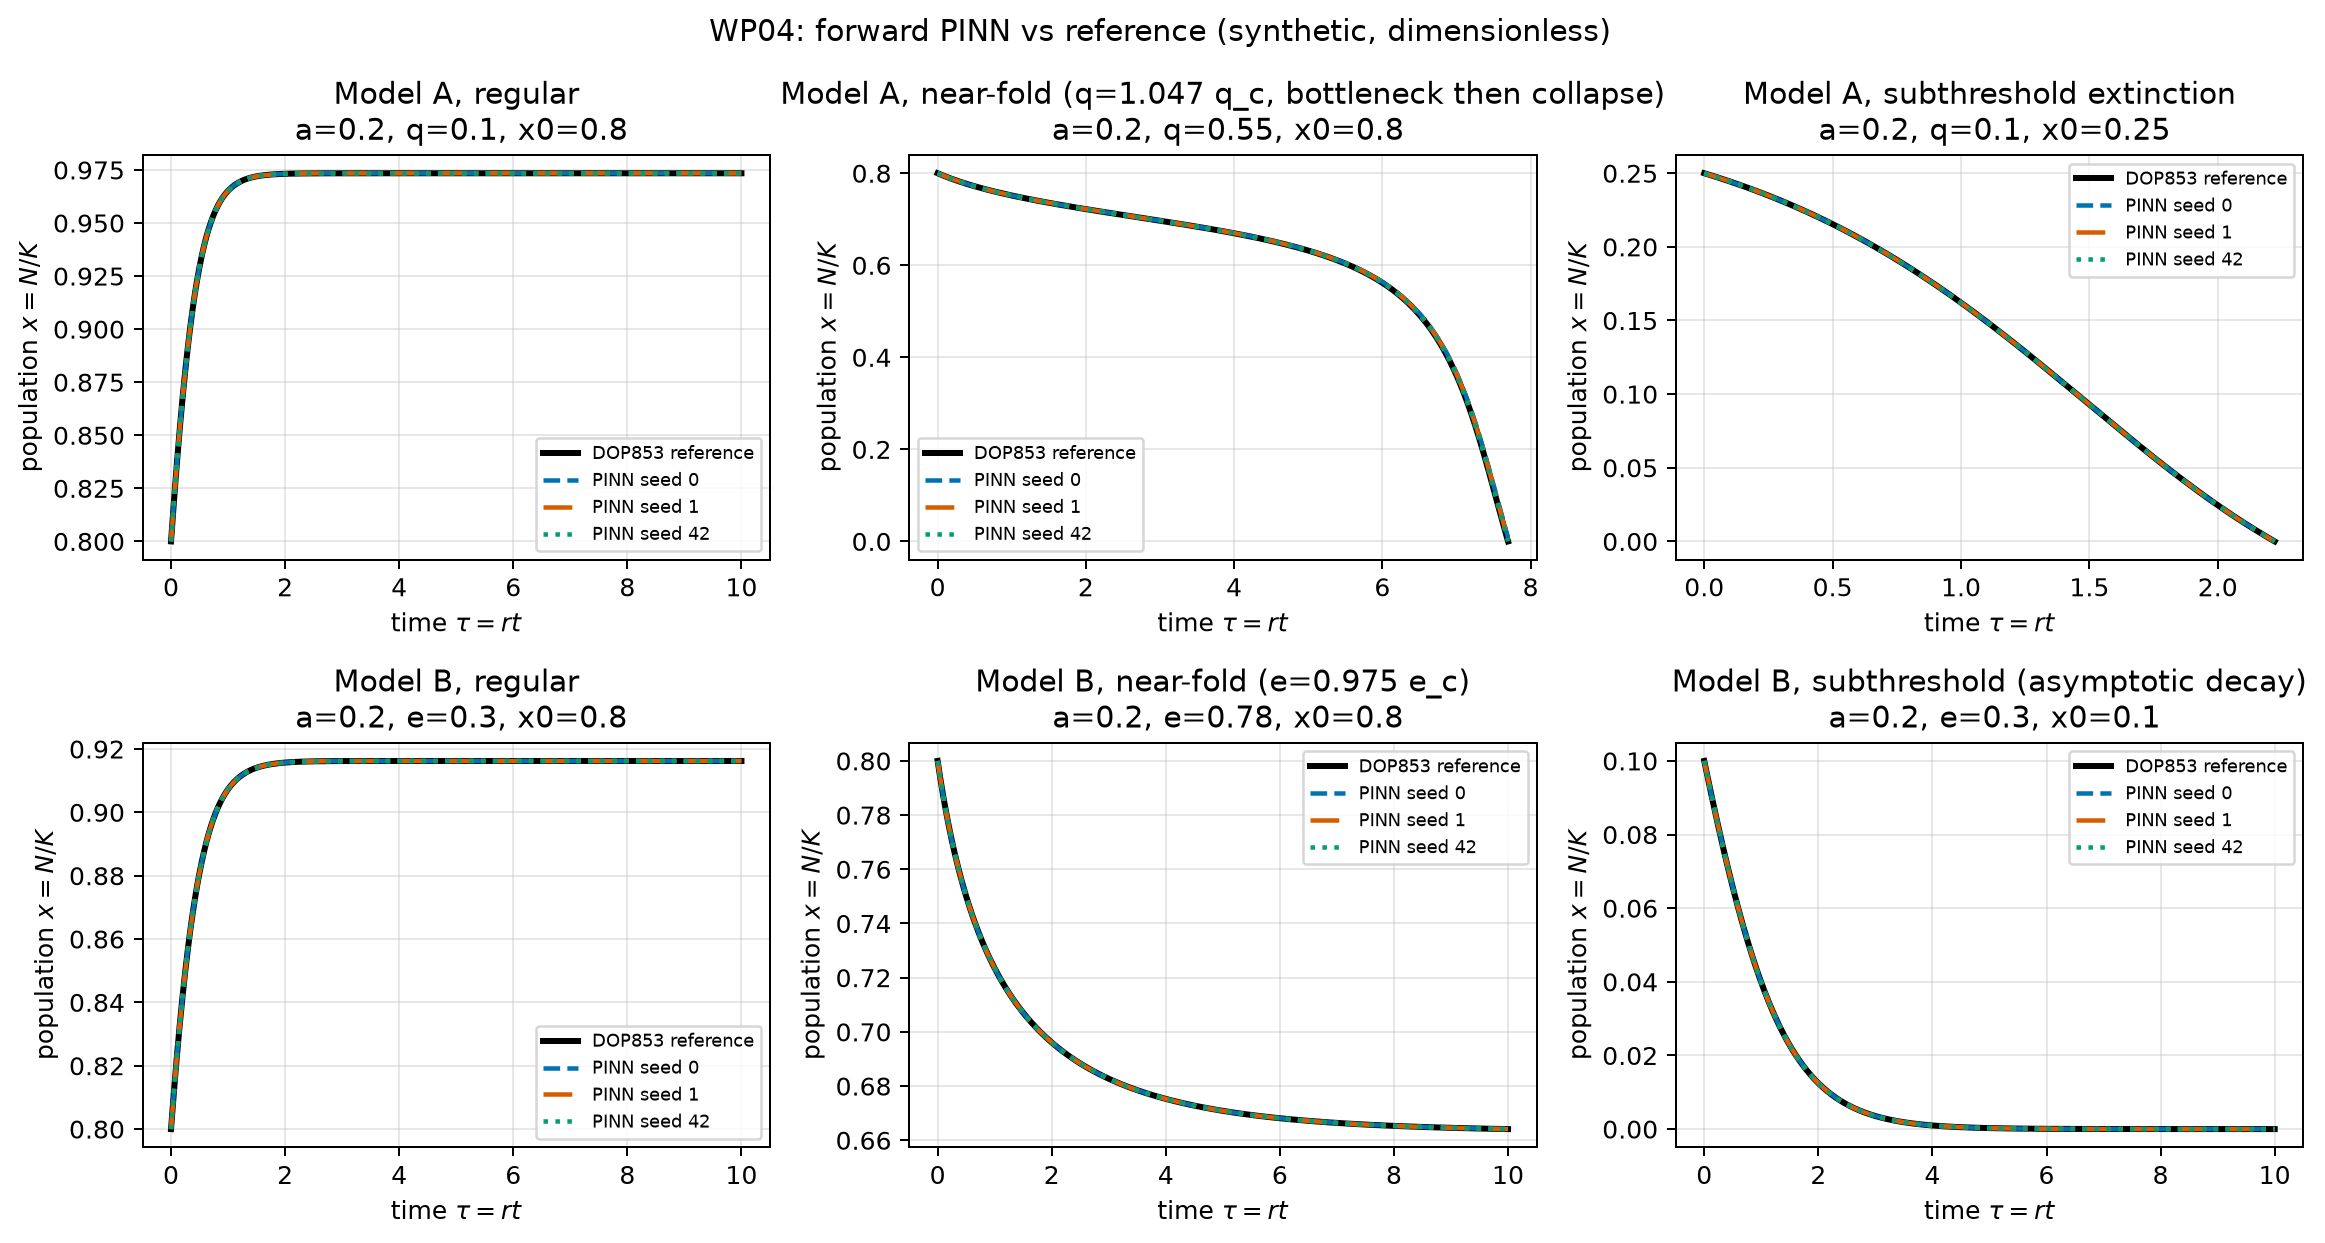

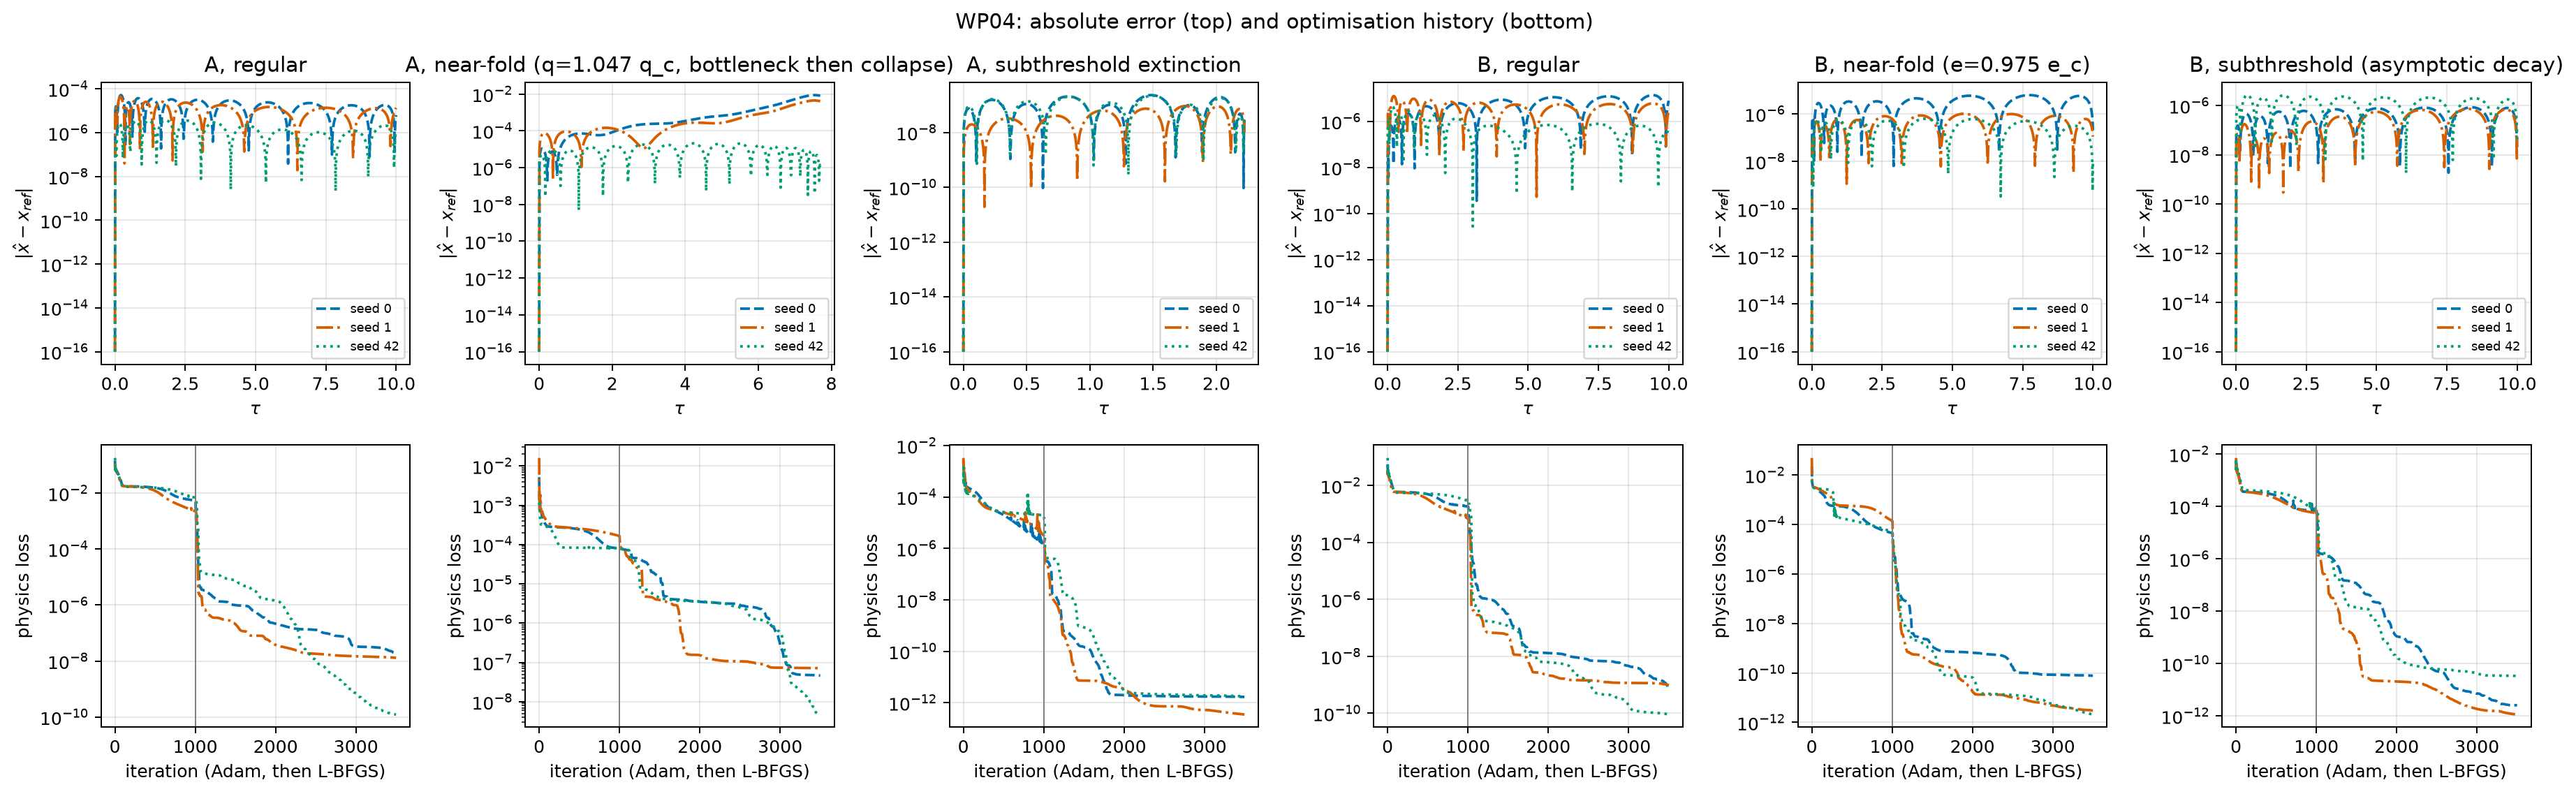

Curated PNGs from the final run (EPS and PDF copies are in `artifacts/figures/`). The vertical line in the bottom row marks the Adam to L-BFGS hand-over.

## Interpretation

- **Final sweep (tanh, lr $10^{-3}$, seeds 0/1/42):** all 18 runs are accurate, relative $L^2$ from $2.9\times10^{-7}$ to $4.1\times10^{-3}$ (median $6.4\times10^{-6}$); the largest error is A near-fold (collapse after a bottleneck), the hardest case.
- Five runs predict slightly negative populations near zero (B decay seeds 1 and 42: 23 and 61 of 1001 samples; A extinction and A near-fold: 1 sample each). Near-zero error (largest absolute error where $x_{\rm ref}<0.05$): A extinction $8.9\times10^{-8}$ to $1.9\times10^{-7}$, B decay $7.3\times10^{-7}$ to $2.6\times10^{-6}$, A near-fold $4.8\times10^{-6}$ to $8.6\times10^{-3}$.
- In every run L-BFGS stopped at its 2500-iteration limit (not an abnormal exit), so the iteration budget is binding; longer runs were not tried.
- RK45 matches the reference to about $10^{-10}$ in $4$ to $10$ ms; each PINN run took $3.2$ to $4.6$ s. For a scalar ODE the classical solver is the better tool; the PINN's value is as the engine for the inverse problem (Section 5).
- For Model A the horizon $T$ is the extinction time from the reference solver: the forward PINN does **not** predict the extinction time itself.
- *Limitations:* one parameter set per regime, three seeds, setting selected on the same seeds (then confirmed on three others, below), one machine; per-seed results depend on platform and library versions (exact versions are in the manifests). A **small training loss is not evidence of accuracy**: see the diagnostic below.


## Held-out confirmation and reproducibility

The frozen design (tanh, $(1,32,32,1)$, lr $10^{-3}$, 300 points) was run unchanged on seeds 11, 22, 33, which were **not** used to select it. Table loaded from `artifacts/tables/wp04_confirmation_metrics.csv` (about 1.2 min on CPU to regenerate with `configs/wp04_confirm.json`). All 18 runs are accurate (A near-fold $1.8\times10^{-4}$ to $2.3\times10^{-3}$ is the largest); both seed sets give **36 of 36 accurate runs**. Reviewers' independent reruns on Linux with newer libraries of the *earlier* swish design (lr $10^{-2}$) reproduced the counts but failed a different A near-fold seed, so per-seed results depend on platform and library versions; the final tanh design has not yet been rerun by another member. The exact versions used here are in `artifacts/manifests/wp04_*_requirements.txt`.

In [ ]:
conf = [
    r
    for r in csv.DictReader(open("artifacts/tables/wp04_confirmation_metrics.csv"))
    if r["method"] == "pinn"
]
for case in dict.fromkeys(r["case"] for r in conf):
    errs = [float(r["relative_l2"]) for r in conf if r["case"] == case]
    print(f"{case:13s} seeds 11/22/33 rel L2: " + ", ".join(f"{e:.1e}" for e in errs))
print("accurate:", sum(float(r["relative_l2"]) <= 5e-2 for r in conf), "of", len(conf))

## Diagnostic: why did the regular cases fail with tanh, 100 points and lr $10^{-2}$?

An *exploratory* experiment (`experiments/wp04/diagnose.py`; hypotheses were written in `experiments/wp04/README.md` before running) on the **earlier** design (tanh, 100 uniform points, learning rate $10^{-2}$, seeds 11/22/33), separate from the final sweep. A regular and B regular are trained with 10 seeds under five collocation designs: `U100` (the earlier design), `U200`, `U400` (denser uniform), `P100` (100 points clustered near $\tau=0$, $\tau_i=T(i/99)^2$) and `U100_long` (10000 L-BFGS iterations). Besides the error we measure the residual $|R|$ on a dense grid *between* the training points. Command: `python experiments/wp04/diagnose.py --config configs/wp04_diagnose.json --output results/wp04_diagnose --artifacts artifacts` (about 8 min on CPU); the table below is loaded, not recomputed.


In [ ]:
for r in csv.DictReader(open("artifacts/tables/wp04_diagnose_summary.csv")):
    med = float(r["median_relative_l2"])
    print(
        f"{r['case']:10s}{r['variant']:10s} accurate {r['n_accurate']:>2s}/10  unstable-root {r['n_unstable_root']:>2s}  "
        f"zero {r['n_zero']:>2s}  negative {r['n_negative_state']:>2s}  not-converged {r['n_not_converged']:>2s}  "
        f"other {r['n_other']:>2s}  median rel L2 {med:.1e}"
    )

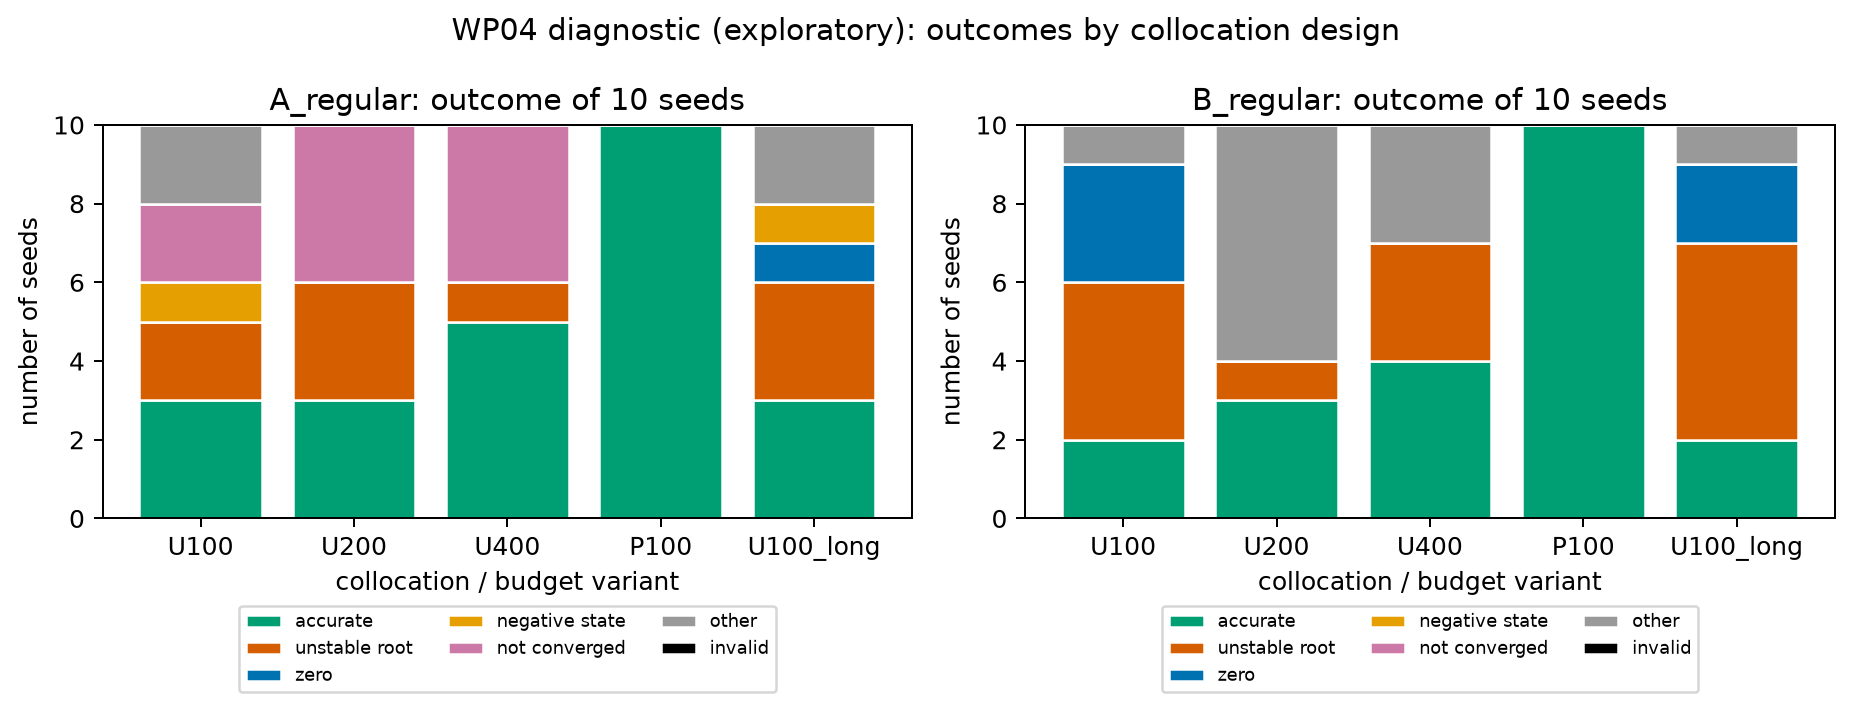

**Findings (10 seeds per cell, tanh, lr $10^{-2}$).**

- **Mechanism:** every accurate run has max dense-grid residual $\le1.2\times10^{-3}$ and every failed run $\ge8.4\times10^{-1}$, yet 45 of the 55 failures had residual $<10^{-1}$ *at the training points*. The loss at the training points cannot reveal them; a residual check on a denser grid separates all 100 runs.
- **Resolution near $\tau=0$ matters, not the point count:** denser uniform grids help only a little (accurate runs: A 3, 3, 5 and B 2, 3, 4 for 100, 200, 400 points), whereas the same 100 points clustered near $\tau=0$ gave 10/10 in both cases (median relative $L^2$ $6.5\times10^{-6}$ for A, $5.3\times10^{-6}$ for B).
- **More L-BFGS iterations do not help:** 3/10 (A) and 2/10 (B) stay accurate.
- Failures end on spurious equilibria of the ODE: the unstable root (22 runs), zero (6), the unphysical negative root of the Model A polynomial (2), or elsewhere; 10 runs had not converged (all Model A, uniform grids).
- The final design (tanh, lr $10^{-3}$, 300 uniform points) does not show these failures (36 of 36 accurate on six seeds); which of the changes (learning rate, number of points) removed them was not isolated.
- *Caveats:* two cases only; the clustered grid was chosen after seeing the failures and was not adopted; 10 seeds cannot exclude a failure rate up to about $25$-$30\%$; outcomes are sensitive to round-off (a grid differing by one rounding unit changed one failing seed's error from $7.6\times10^{-1}$ to $9.8\times10^{-1}$).


# 5. Inverse PINNs, Identifiability, and Held-Out Validation

**Owner:** @rohanagrawal28 (WP05)

In this section, we estimate unknown parameters of strong-Allee harvesting models from discrete, noisy population observations.
We investigate two central questions:
1. **Structural Identifiability:** Are model parameters uniquely determined by ideal observation trajectories?
2. **Inference & Generalization:** How accurately can parameters and held-out future states be predicted under measurement noise using conventional ODE least squares versus Physics-Informed Neural Networks (PINNs)?

<div style="border-left:4px solid #c87116;padding:10px"><strong>Current review limitation.</strong> The source trainer still has two reporting findings open in PR #10: validation loss history can be undefined when selection is disabled, and an optimizer failure can be labelled converged. The parameter/prediction comparisons below remain measurements, but the status label alone is not proof of optimizer convergence. These findings do not establish that the historical fits actually failed.</div>

In [ ]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Automatic Colab & Local path detection
if "google.colab" in sys.modules:
    for candidate in [
        Path.cwd(),
        Path("/content"),
        Path("/content/Rohan_RK45_Data_and_Code"),
        Path("/content/mm-allee-harvesting"),
    ]:
        if (candidate / "src/mm_allee").exists():
            if str(candidate / "src") not in sys.path:
                sys.path.insert(0, str(candidate / "src"))
            os.chdir(candidate)
            break
else:
    ROOT = next(
        (
            p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src/mm_allee").exists()
        ),
        None,
    )
    if ROOT is not None and str(ROOT / "src") not in sys.path:
        sys.path.insert(0, str(ROOT / "src"))

from mm_allee.data import generate_noisy_observations
from mm_allee.inference import fit_ode_least_squares
from mm_allee.models import Parameters
from mm_allee.solver import solve_trajectory

print("Loaded shared modules successfully.")

## 5.1 Model B Structural Nonidentifiability and Counterexample

Under Model B, harvesting is proportional to population density ($h N$):
$$\frac{dN}{dt} = r N \left(1 - \frac{N}{K}\right)\left(\frac{N}{A} - 1\right) - h N$$

Expanding the cubic polynomial:
$$\frac{dN}{dt} = -(r + h) N + r\left(\frac{1}{A} + \frac{1}{K}\right) N^2 - \frac{r}{AK} N^3$$

Any trajectory observed at a single constant effort $h$ reveals at most **three** composite polynomial combinations:
$$c_1 = -(r + h), \quad c_2 = r\left(\frac{1}{A} + \frac{1}{K}\right) = \frac{r(A+K)}{AK}, \quad c_3 = -\frac{r}{AK}$$

Because there are 4 unknown physical parameters $(r, A, K, h)$ but only 3 observable coefficients, the system is **structurally nonidentifiable** from data at a single fixed effort.

In [ ]:
# Demonstrate the exact two-parameter-set counterexample:
p1 = Parameters(r=1.0, A=0.2, K=1.0, h=0.5)
p2 = Parameters(r=1.35, A=0.3, K=0.9, h=0.15)

c1_1, c2_1, c3_1 = -(p1.r + p1.h), p1.r * (1.0 / p1.A + 1.0 / p1.K), -p1.r / (p1.A * p1.K)
c1_2, c2_2, c3_2 = -(p2.r + p2.h), p2.r * (1.0 / p2.A + 1.0 / p2.K), -p2.r / (p2.A * p2.K)

print(f"Parameter Set 1: c1={c1_1:.2f}, c2={c2_1:.2f}, c3={c3_1:.2f}")
print(f"Parameter Set 2: c1={c1_2:.2f}, c2={c2_2:.2f}, c3={c3_2:.2f}")
assert np.isclose(c1_1, c1_2) and np.isclose(c2_1, c2_2) and np.isclose(c3_1, c3_2)

# Solve trajectories from three distinct initial states for both parameter sets
d1, d2 = p1.dimensionless(), p2.dimensionless()
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for n0, color in zip([0.4, 0.7, 1.1], colors, strict=True):
    traj1 = solve_trajectory(
        "B", a=d1["a"], harvest=d1["e"], x0=n0 / p1.K, tau_end=p1.r * 4.0, n_points=81
    )
    traj2 = solve_trajectory(
        "B", a=d2["a"], harvest=d2["e"], x0=n0 / p2.K, tau_end=p2.r * 4.0, n_points=81
    )
    t1, y1 = traj1.tau / p1.r, traj1.x * p1.K
    t2, y2 = traj2.tau / p2.r, traj2.x * p2.K
    ax.plot(t1, y1, label=f"Set 1 (N0={n0})", color=color, lw=2)
    ax.plot(t2, y2, "--", label=f"Set 2 (N0={n0})", color="black", alpha=0.7)

ax.set_title(
    "Model B Identifiability Counterexample: Identical Trajectories from Different Parameters"
)
ax.set_xlabel("Time t")
ax.set_ylabel("Population N(t)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 5.2 Observations, Noise Generation, and Frozen 60/20/20 Splits

We construct noisy observations according to the contract:
$$N_{\text{obs}}(t_i) = N_{\text{clean}}(t_i) + \sigma \cdot N_{\text{ref}} \cdot \epsilon_i, \quad \epsilon_i \sim \mathcal{N}(0, 1)$$
with fixed external scale $N_{\text{ref}} = 100.0$. Observations are never silently clipped. Each trajectory has **101 observations** on $t\in[0,8]$.

Splits are strictly partitioned into contiguous time windows:
- **Train (60%, 61 points, $t\le4.8$):** used exclusively for fitting and data loss.
- **Validation (20%, 20 points, $4.88\le t\le6.4$):** never in the gradient; reported, and optionally used for early stopping (switched **off** in the final setting, see 5.4).
- **Held-out Test (20%, 20 points, $6.48\le t\le8$):** completely frozen until final post-training evaluation.

In [ ]:
p_true = Parameters(r=0.7, K=100.0, A=20.0, H=10.0)
d_true = p_true.dimensionless()
ref_traj = solve_trajectory(
    "A", a=d_true["a"], harvest=d_true["q"], x0=45.0 / 100.0, tau_end=0.7 * 8.0, n_points=101
)
times = ref_traj.tau / 0.7
clean_pops = ref_traj.x * 100.0

obs_5pct = generate_noisy_observations(
    times,
    clean_pops,
    trajectory_id="a_regular",
    model="A",
    noise_sigma=0.05,
    noise_seed=11,
    n_ref=100.0,
)

idx_tr, idx_va, idx_te = (
    obs_5pct["train_indices"],
    obs_5pct["val_indices"],
    obs_5pct["test_indices"],
)
print(f"Train points: {len(idx_tr)} (0 to {times[idx_tr[-1]]:.2f})")
print(f"Val points:   {len(idx_va)} ({times[idx_va[0]]:.2f} to {times[idx_va[-1]]:.2f})")
print(f"Test points:  {len(idx_te)} ({times[idx_te[0]]:.2f} to {times[idx_te[-1]]:.2f})")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axvspan(0, times[idx_tr[-1]], color="blue", alpha=0.1, label="Train Split (60%)")
ax.axvspan(times[idx_tr[-1]], times[idx_va[-1]], color="green", alpha=0.1, label="Val Split (20%)")
ax.axvspan(times[idx_va[-1]], times[-1], color="red", alpha=0.1, label="Held-out Test (20%)")
ax.plot(times, clean_pops, "k-", lw=2, label="Clean Reference")
ax.scatter(
    times,
    obs_5pct["observed_population"],
    color="darkblue",
    s=20,
    alpha=0.6,
    label="Noisy Observations (5% noise)",
)
ax.set_title("Model A: Observation Splits and Noise Structure")
ax.set_xlabel("Time t")
ax.set_ylabel("Population N(t)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5.3 Conventional Nonlinear Least-Squares ODE Baseline

We fit unknown parameters using SciPy's Trust Region Reflective solver on training observations only, with known $K=100.0$ and bounds $r > 0, 0 < A < K, H \ge 0$.

In [ ]:
fit_res = fit_ode_least_squares(
    "A",
    observations=obs_5pct,
    known_conditions={"known_K": 100.0, "known_initial_population": 45.0},
    fit_params=["r", "A", "H"],
    initial_guess={"r": 1.0, "A": 30.0, "H": 5.0},
    n_ref=100.0,
)

print(f"ODE Fit Status: {fit_res.status} in {fit_res.wall_seconds:.3f}s")
print("Estimated Parameters:")
for p in ["r", "A", "H"]:
    true_v = getattr(p_true, p)
    est_v = fit_res.estimated_parameters[p]
    rel_err = abs(est_v - true_v) / true_v * 100
    print(f"  {p}: True = {true_v:.2f}, Estimated = {est_v:.4f} (Error: {rel_err:.2f}%)")

print("Held-out Test Performance:")
print(
    f"  RMSE: {fit_res.test_metrics['rmse']:.4f}, Relative L2: {fit_res.test_metrics['relative_l2']:.4f}"
)

## 5.4 Inverse PINN with Differentiable Constraints

We optimize network weights and physical parameters jointly, preserving gradients via:
$$r = \mathrm{softplus}(\tilde{r}) > 0, \quad A = K \cdot \sigma(\tilde{A}) \in (0, K), \quad H = \mathrm{softplus}(\tilde{H}) \ge 0$$
Training loss is evaluated **strictly on training observations** plus the physics residual at 300 collocation points. The network, the network learning rate, the collocation count and the Adam (1000) + L-BFGS (2500) budget are the **same shared setting as the forward problem** (tanh, two hidden layers of 32, learning rate $10^{-3}$); only $\lambda_{\rm phys}=0.1$, the parameter learning rate $10^{-3}$ and the validation option are inverse-specific. Validation-based early stopping is switched off because on a flat late-time window it can return an early, barely trained state (see 5.6). The demo below uses noise $\sigma=0.01$, where Model A regular is informative.

In [ ]:
try:
    import jax  # noqa: F401  (availability check)

    base = next(
        p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiments/integration").exists()
    )
    sys.path.insert(0, str(base / "experiments/integration"))
    from shared_settings import crb_relative_sd

    from mm_allee.pinn.inverse import InversePINNTrainer, TrainableParameters
    from mm_allee.pinn.network import NetworkConfig

    sigma = 0.01
    obs_noisy = generate_noisy_observations(
        times,
        clean_pops,
        trajectory_id="a_regular",
        model="A",
        noise_sigma=sigma,
        noise_seed=11,
        n_ref=100.0,
    )
    known = {"known_initial_population": 45.0, "known_K": 100.0}
    ncfg = NetworkConfig(layers=(1, 32, 32, 1), activation="tanh", seed=1011)
    tp = TrainableParameters(
        "A",
        fit_params=["r", "A", "H"],
        known_conditions={"known_K": 100.0},
        initial_guesses={"r": 1.0, "A": 30.0, "H": 5.0},
    )
    trainer = InversePINNTrainer(
        network_config=ncfg,
        trainable_params=tp,
        lr_net=1e-3,
        lr_params=1e-3,
        lambda_data=1.0,
        lambda_phys=0.1,
        lbfgs_iters=2500,
        lbfgs_ftol=0.0,
        lbfgs_gtol=0.0,
        validation_selection=False,
    )
    pinn_res = trainer.fit(
        obs_noisy, known_conditions=known, epochs=1000, n_collocation=300, seed=1011
    )

    train_t = np.asarray(obs_noisy["time"])[np.asarray(obs_noisy["split"]) == "train"]
    bound = crb_relative_sd(
        "A",
        ["r", "A", "H"],
        {"known_K": 100.0, "known_initial_population": 45.0},
        {"r": 0.7, "K": 100.0, "A": 20.0, "H": 10.0, "h": 0.0},
        train_t,
        sigma * 100.0,
    )
    floor = pinn_res.train_metrics["rmse"] / (sigma * 100.0)
    print(f"PINN completed: {pinn_res.status} in {pinn_res.wall_seconds:.1f}s")
    print(
        f"training RMSE / noise sd = {floor:.2f}  (about 0.9 means the fit reached the noise floor)"
    )
    for p in ["r", "A", "H"]:
        true_v = getattr(p_true, p)
        est_v = pinn_res.estimated_parameters[p]
        rel_err = abs(est_v - true_v) / true_v
        print(
            f"  {p}: true {true_v:.2f}, PINN {est_v:.4f}, relative error {rel_err:.1e}, "
            f"Cramer-Rao bound {bound[p]:.1e}"
        )
except ImportError:
    print(
        "JAX is not installed in this environment; skipping PINN training. Full code is implemented in mm_allee.pinn."
    )

## 5.5 Final sweep results (loaded from `artifacts/`, not retrained)

`python experiments/wp05/run.py --config configs/wp05_final.json --output results/wp05` runs 6 cases $\times$ 3 noise levels $\times$ 3 seeds = 54 PINN fits and 54 ODE fits. The table below counts the **clean-data** fits ($\sigma=0$) in which *every* fitted parameter is within $5\times10^{-2}$ relative error. Rohan's original settings (64x64, 120 points, validation early stopping, 200 L-BFGS iterations) recovered 0 of 18 and all 54 of their fits ended `validation_stopped`.

In [ ]:
import csv  # noqa: F811  (an earlier fragment imports csv in the assembled notebook)
import statistics

rows = list(csv.DictReader(open("artifacts/tables/wp05_parameter_metrics.csv")))
fits = {}
for r in rows:
    if float(r["noise_sigma"]) == 0.0:
        fits.setdefault((r["method"], r["run_id"]), {})[r["parameter"]] = float(r["relative_error"])
cases = ["a_regular", "b_regular", "a_extinction", "b_near_fold", "a_near_fold", "b_decline"]
print(f"{'case':14s}{'PINN recovered':>16s}{'PINN median err':>17s}{'ODE_LS median err':>19s}")
total = 0
for c in cases:
    pinn = [max(v.values()) for (m, rid), v in fits.items() if m == "PINN" and f"wp05_{c}_" in rid]
    ode = [max(v.values()) for (m, rid), v in fits.items() if m == "ODE_LS" and f"wp05_{c}_" in rid]
    ok = sum(e <= 0.05 for e in pinn)
    total += ok
    print(
        f"{c:14s}{ok:>13d}/{len(pinn)}{statistics.median(pinn):>17.1e}{statistics.median(ode):>19.1e}"
    )
print(f"PINN total recovered (every parameter within 5e-2): {total}/18   (original settings: 0/18)")

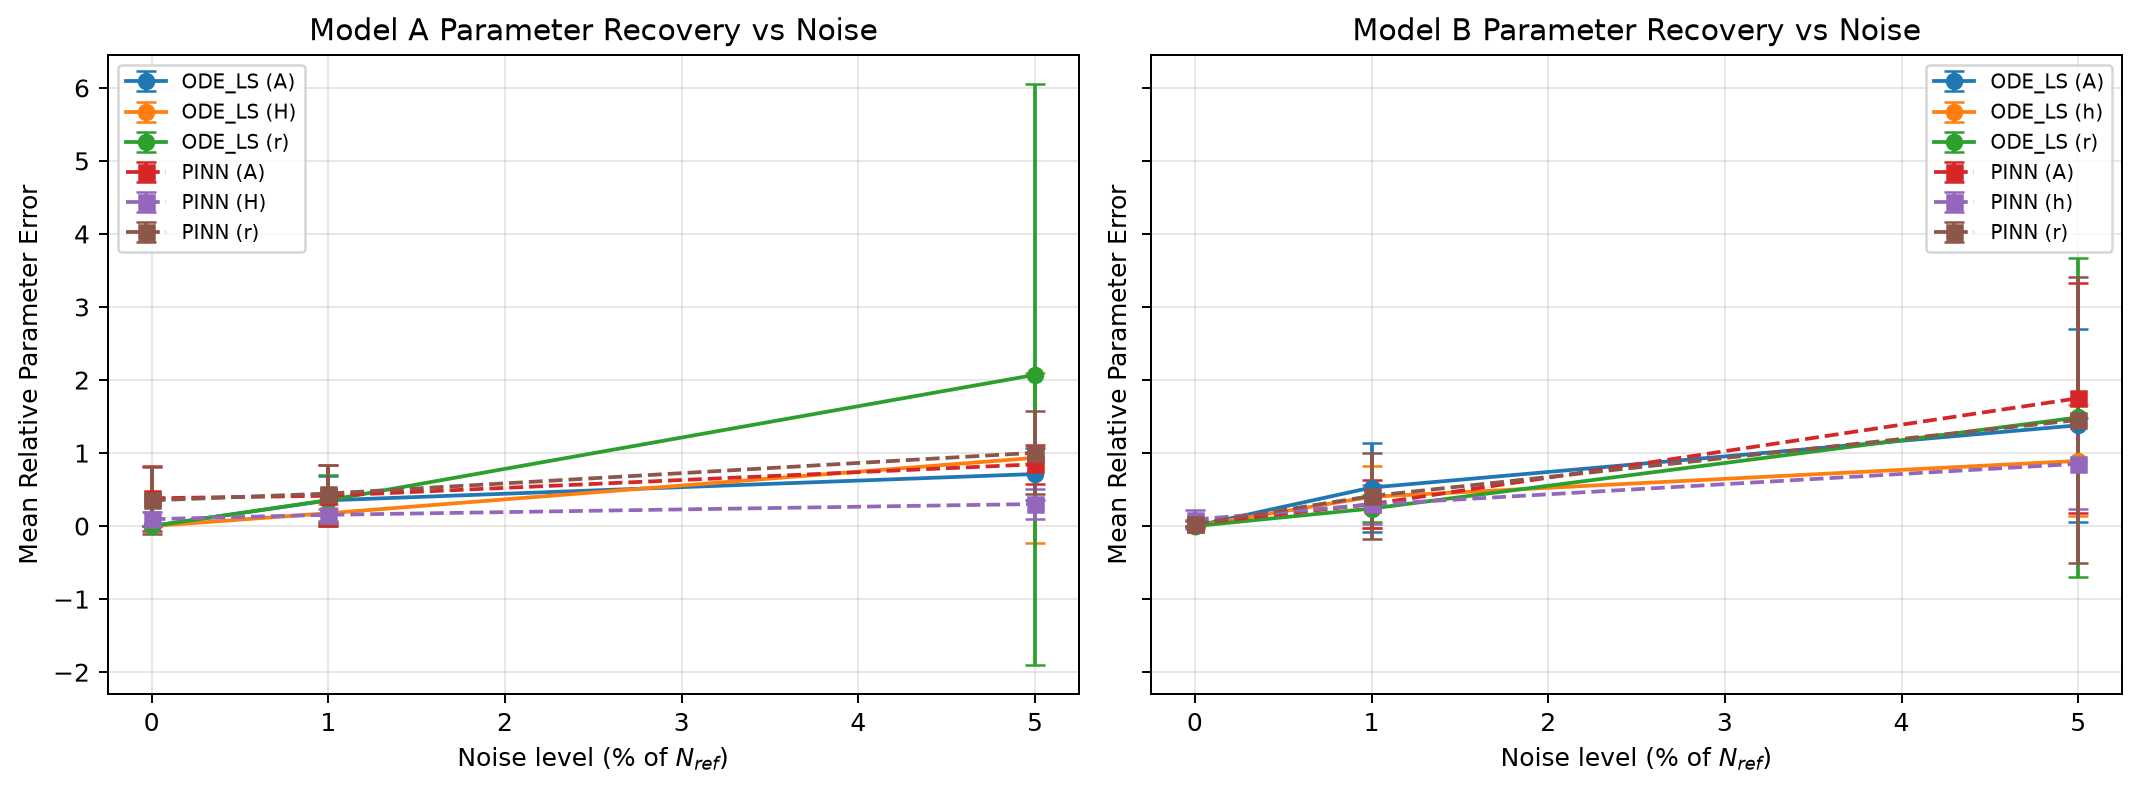

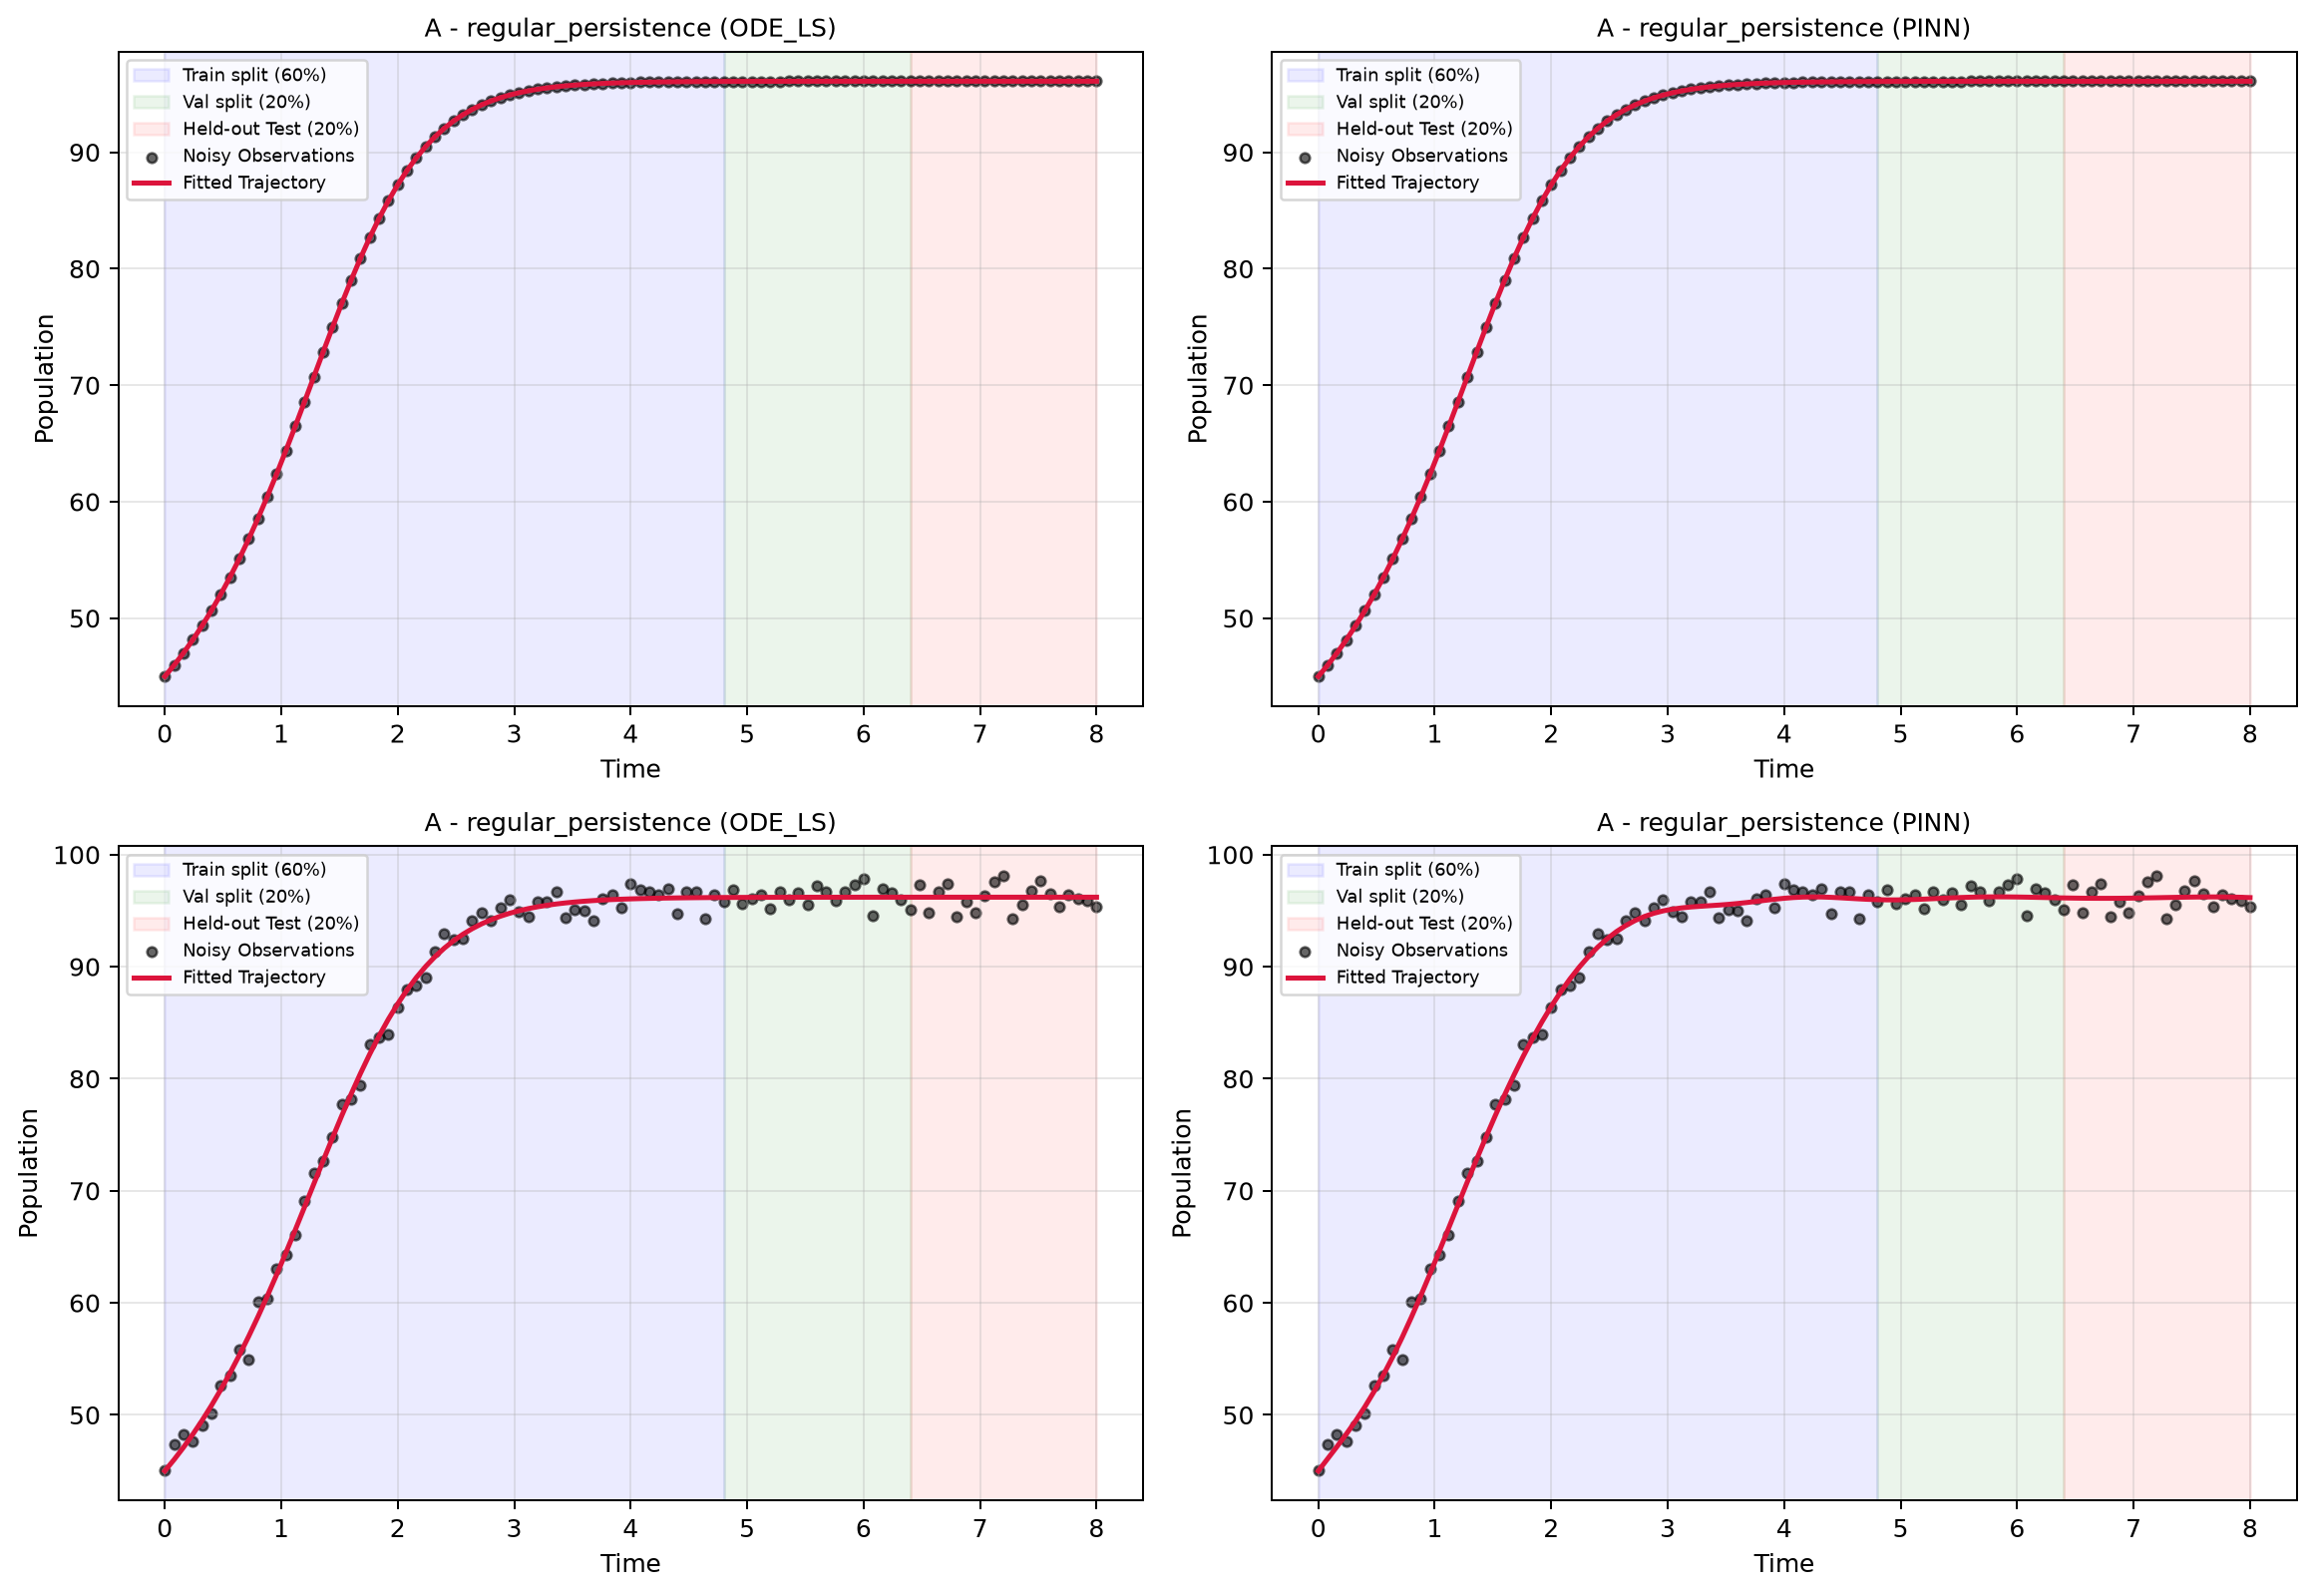

The first figure averages over all six cases and seeds, so its error bars are dominated by the badly conditioned cases. The second shows Model A regular (top row noise-free, bottom row noisy); the regular trajectories are at equilibrium by $t=4.8$, so the held-out window is an undemanding extrapolation test.

## 5.6 Why some cases cannot be recovered, and whether noise is the reason

- **Practical non-identifiability.** Model A near-fold, Model B near-fold and Model B decline have Jacobian condition numbers of $10^{3}$ to $2\times10^{4}$ (62 to 340 for the recoverable cases). The PINN fits the training data to $10^{-4}$ to $10^{-5}$ while the parameters are off by 40% to 100%; the ODE fit reaches $10^{-7}$ to $10^{-10}$, so the problems are identifiable in principle. In the near-fold cases $r$ and $A$ collapse together to about $10^{-6}$ with $r/A$ fixed, a degenerate valley of the cubic. No hyperparameter fixed this.
- **Noise is not the cause.** At $\sigma\in\{0,0.001,0.005,0.01\}$ (tanh and swish, 144 fits) the optimiser reaches the noise floor in 132 of 144 fits; well-conditioned errors are about 1.3 to 1.4 times the Cramér–Rao bound at every $\sigma$; the share of collapsed fits does not depend on $\sigma$.
- **The 12 fits that missed the noise floor** all came from validation-based early stopping (status `validation_stopped`, parameters still at the starting guess). Switched off, all 144 fits reach the noise floor, but recovery does not improve overall: the remaining failures are structural.
- **Judge noisy recovery against the Cramér–Rao bound.** At $\sigma=0.01$ only Model A and B regular are informative (bound at most 25%); there the shared setting is within twice the bound in 6 of 6 fits (original settings 0 of 6). At $\sigma=0.05$ no case is informative.

## 5.7 Key Scientific Takeaways

1. **Parameter Error $\ne$ Trajectory Error:** the PINN fits every case to about $10^{-4}$ or better but recovers the parameters only where the problem is well conditioned (10 of 18 clean fits), and under noise only as well as the Cramér–Rao bound allows.
2. **Classical ODE Baselines are Strong:** for scalar ODEs with low-dimensional parameter spaces, SciPy nonlinear least squares is faster and recovers all six cases on clean data.
3. **Structural Identifiability Precedes Optimization:** Model B with unknown effort $h$ is mathematically ambiguous; no optimization algorithm can break this ambiguity without additional independent information (e.g. known $K$ or multiple effort levels).
4. **Check convergence against the noise level:** a short L-BFGS budget with a tolerance stop and validation-based checkpoint selection silently returned near-initial parameters in every run of the original sweep; the ratio of training RMSE to noise sd exposes this.